<a href="https://colab.research.google.com/github/ahmedyussuf4/FaciaMatch-Project/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [74]:
# Add code here 🔧


## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [75]:
import pandas as pd

url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_historical_data.csv'
df = pd.read_csv(url)

print("--- Dataframe Info ---")
print(df.info())

print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Descriptive Statistics ---")
display(df.describe(include='all'))

print("\n--- Missing Values Count ---")
print(df.isnull().sum())

print("\n--- Duplicate Rows Count ---")
print(df.duplicated().sum())

print("\n--- Range checks (Min/Max values) to detect potential outliers ---")
print(df[['income', 'age', 'num_dependents', 'num_accts']].agg(['min', 'max']))

--- Dataframe Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB
None

--- First 5 Rows ---


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
1,184,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
2,194,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
3,689,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
4,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0



--- Descriptive Statistics ---


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
unique,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,27903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,14850.475563,0.546638,33766.893303,NaN,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,NaN,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,NaN,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,NaN,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,NaN,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,NaN,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000



--- Missing Values Count ---
customer_id       0
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           2
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
product           0
dtype: int64

--- Duplicate Rows Count ---
3

--- Range checks (Min/Max values) to detect potential outliers ---
     income  age  num_dependents  num_accts
min  -65600   19               1          0
max  159450  132               2       3345


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. In the initial data preview, several anomalies stand out: the income column contains a negative minimum value of -65,600, the age column contains an unrealistic maximum age of 132, and the num_accts column has an extreme maximum of 3,345 accounts which deviates heavily from the average. Additionally, the female column is incorrectly loaded as text or object format instead of a clean binary representation, there are 2 missing values in the new_car column, and there are 3 completely duplicate rows in the dataset.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [76]:
# Add code here 🔧

In [77]:
df_clean = df.drop_duplicates().copy()

df_clean = df_clean[df_clean['income'] >= 0]

df_clean = df_clean[df_clean['age'] < 100]

df_clean = df_clean[df_clean['num_accts'] < 20]


mode_new_car = df_clean['new_car'].mode()[0]
df_clean['new_car'] = df_clean['new_car'].fillna(mode_new_car)


columns_to_drop = ['customer_id', 'product']
df_clean = df_clean.drop(columns=columns_to_drop, errors='ignore')

# Display cleaned dataframe info
print("--- Cleaned Dataframe Info ---")
print(df_clean.info())
print("\n--- Cleaned Summary Statistics ---")
display(df_clean.describe())

--- Cleaned Dataframe Info ---
<class 'pandas.core.frame.DataFrame'>
Index: 29497 entries, 1 to 29503
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   answered        29497 non-null  int64  
 1   income          29497 non-null  int64  
 2   female          29497 non-null  object 
 3   age             29497 non-null  int64  
 4   job             29497 non-null  int64  
 5   num_dependents  29497 non-null  int64  
 6   rent            29497 non-null  int64  
 7   own_res         29497 non-null  int64  
 8   new_car         29497 non-null  float64
 9   chk_acct        29497 non-null  int64  
 10  sav_acct        29497 non-null  int64  
 11  num_accts       29497 non-null  int64  
 12  mobile          29497 non-null  int64  
dtypes: float64(1), int64(11), object(1)
memory usage: 3.2+ MB
None

--- Cleaned Summary Statistics ---


,answered,income,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
count,29497.000000,29497.000000,29497.000000,29497.000000,29497.000000,29497.000000,29497.000000,29497.000000,29497.000000,29497.000000,29497.000000,29497.000000
mean,0.546700,33775.860596,34.770994,1.915449,1.141031,0.210360,0.681154,0.240770,1.468319,0.956572,2.345323,0.091128
std,0.497823,29373.742541,11.355178,0.658217,0.348060,0.407571,0.466037,0.427558,1.234706,1.483996,1.200626,0.287796
min,0.000000,2760.000000,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,13550.000000,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000
50%,1.000000,23310.000000,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000
75%,1.000000,41690.000000,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000
max,1.000000,159450.000000,74.000000,3.000000,2.000000,1.000000,1.000000,1.000000,3.000000,4.000000,8.000000,1.000000


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5
- For outliers, I dropped negative incomes, ages over 100, and accounts over 20 because they skewed the data.
- For missing data, I filled in the blank new_car spots with the mode because it is a yes/no variable, and filling it with the most common answer makes the most sense.

2.6
- I removed customer_id because it is just a random ID number and does not help predict anything.
- I also removed product because that data is only recorded after a customer answers the call, so including it in our prediction model would be cheating.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [78]:

df_clean['answered'] = df_clean['answered'].astype(bool)


df_clean['new_car'] = df_clean['new_car'].astype(int)


print(df_clean[['answered', 'new_car']].dtypes)
print("\nFirst 5 rows of standardized variables:")
display(df_clean[['answered', 'new_car']].head())

answered     bool
new_car     int64
dtype: object

First 5 rows of standardized variables:


,answered,new_car
1,False,0
2,False,0
3,False,0
4,False,0
6,False,0


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [79]:

categorical_cols = ['job', 'chk_acct', 'sav_acct']
for col in categorical_cols:
    df_clean[col] = df_clean[col].astype('category')


print(df_clean[categorical_cols].dtypes)
print("\nFirst 5 rows of categorical variables:")
display(df_clean[categorical_cols].head())

job         category
chk_acct    category
sav_acct    category
dtype: object

First 5 rows of categorical variables:


,job,chk_acct,sav_acct
1,2,1,3
2,2,3,0
3,2,1,3
4,2,3,0
6,2,3,0


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



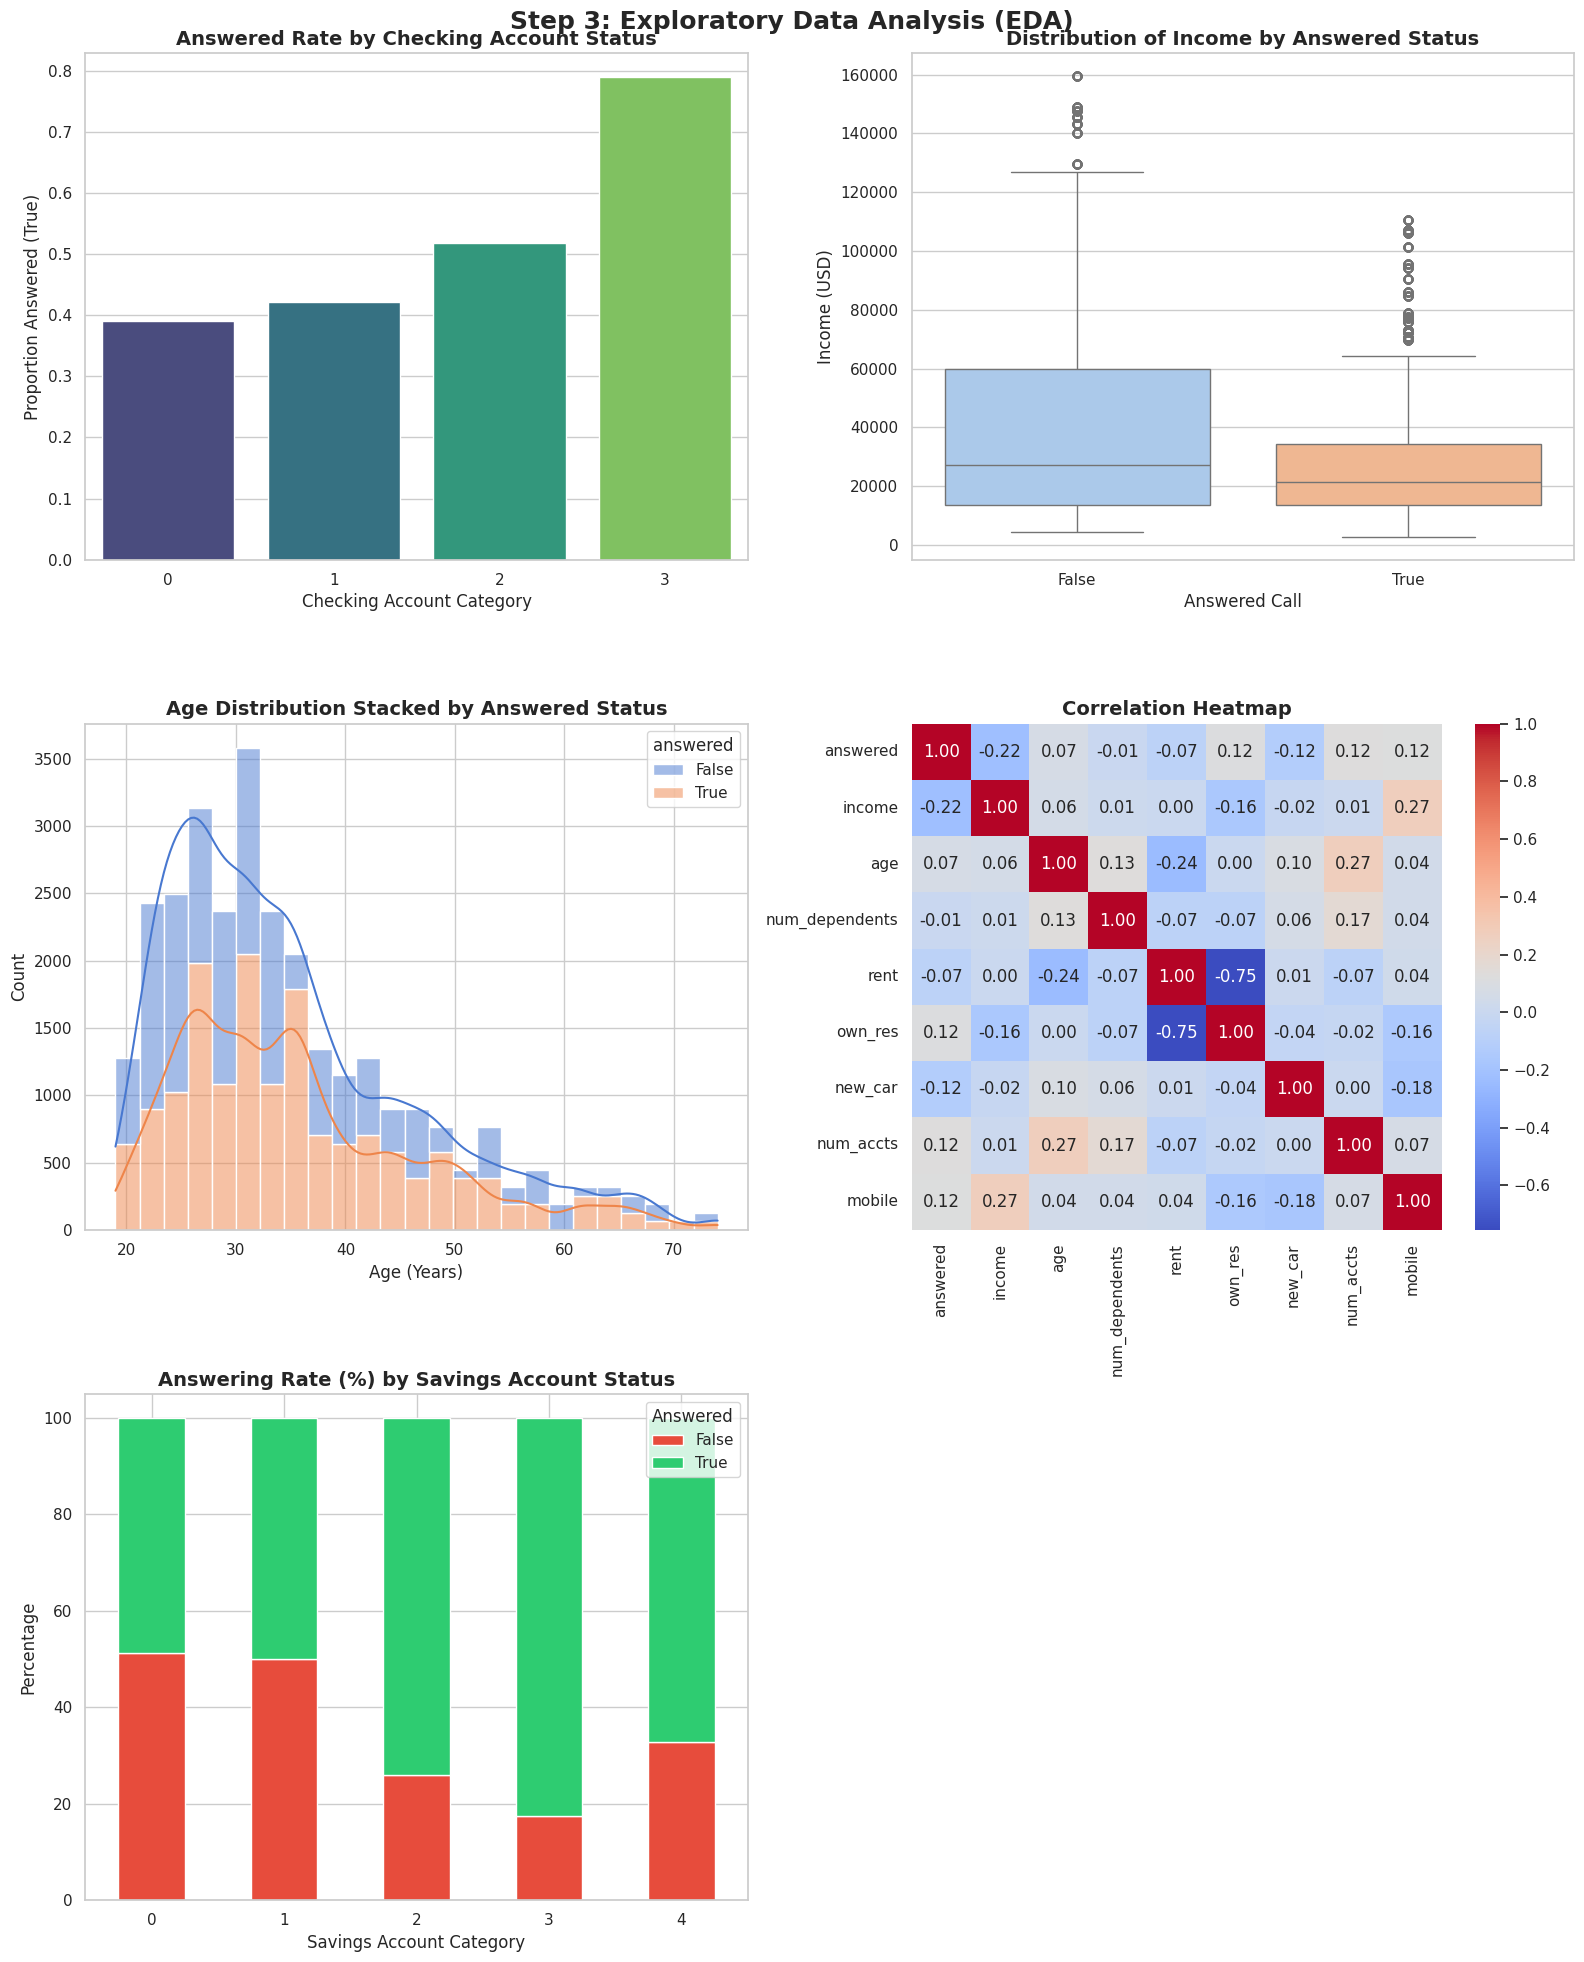

In [80]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np


sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(16, 20))
fig.suptitle("Step 3: Exploratory Data Analysis (EDA)", fontsize=18, fontweight='bold', y=0.98)

# 1. Bar Plot
sns.barplot(ax=axes[0, 0], data=df_clean, x='chk_acct', y='answered', hue='chk_acct', legend=False, errorbar=None, palette='viridis')
axes[0, 0].set_title("Answered Rate by Checking Account Status", fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel("Checking Account Category", fontsize=12)
axes[0, 0].set_ylabel("Proportion Answered (True)", fontsize=12)

# 2. Box Plot
sns.boxplot(ax=axes[0, 1], data=df_clean, x='answered', y='income', hue='answered', legend=False, palette='pastel')
axes[0, 1].set_title("Distribution of Income by Answered Status", fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel("Answered Call", fontsize=12)
axes[0, 1].set_ylabel("Income (USD)", fontsize=12)

# 3. Histogram/KDE
sns.histplot(ax=axes[1, 0], data=df_clean, x='age', hue='answered', multiple='stack', kde=True, bins=25, palette='muted')
axes[1, 0].set_title("Age Distribution Stacked by Answered Status", fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel("Age (Years)", fontsize=12)
axes[1, 0].set_ylabel("Count", fontsize=12)

# 4. Correlation Heatmap
numeric_cols = df_clean.select_dtypes(include=['int64', 'float64', 'int32', 'bool']).columns
corr_matrix = df_clean[numeric_cols].corr()
sns.heatmap(ax=axes[1, 1], data=corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
axes[1, 1].set_title("Correlation Heatmap", fontsize=14, fontweight='bold')

#5. Stacked Bar Chart
savings_answered = pd.crosstab(df_clean['sav_acct'], df_clean['answered'], normalize='index') * 100
savings_answered.plot(kind='bar', stacked=True, ax=axes[2, 0], color=['#e74c3c', '#2ecc71'])
axes[2, 0].set_title("Answering Rate (%) by Savings Account Status", fontsize=14, fontweight='bold')
axes[2, 0].set_xlabel("Savings Account Category", fontsize=12)
axes[2, 0].set_ylabel("Percentage", fontsize=12)
axes[2, 0].legend(title="Answered", labels=["False", "True"])
axes[2, 0].tick_params(axis='x', rotation=0)


axes[2, 1].axis('off')

plt.tight_layout()
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response:
3.6. Checking account status and savings account status show the strongest relationships. Customers with larger balances in these accounts are much more likely to answer. Income also shows a moderate relationship, with lower-income customers answering slightly more often.

3.7. Yes, number of dependents and having a new car have almost no correlation with answering. However, we should keep them for now because machine learning models might still find helpful patterns when combining them with other features.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [81]:

base_prob = df_clean['answered'].mean()

print(f"Total Cleaned Records: {len(df_clean)}")
print(f"Number of Answers: {df_clean['answered'].sum()}")
print(f"Base Probability of Answering: {base_prob:.4f} ({base_prob * 100:.2f}%)")

Total Cleaned Records: 29497
Number of Answers: 16126
Base Probability of Answering: 0.5467 (54.67%)


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [82]:
from sklearn.model_selection import train_test_split


X = df_clean.drop(columns=['answered'])
y = df_clean['answered']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set size (X_train): {X_train.shape}")
print(f"Testing set size (X_test): {X_test.shape}")

Training set size (X_train): (23597, 12)
Testing set size (X_test): (5900, 12)


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

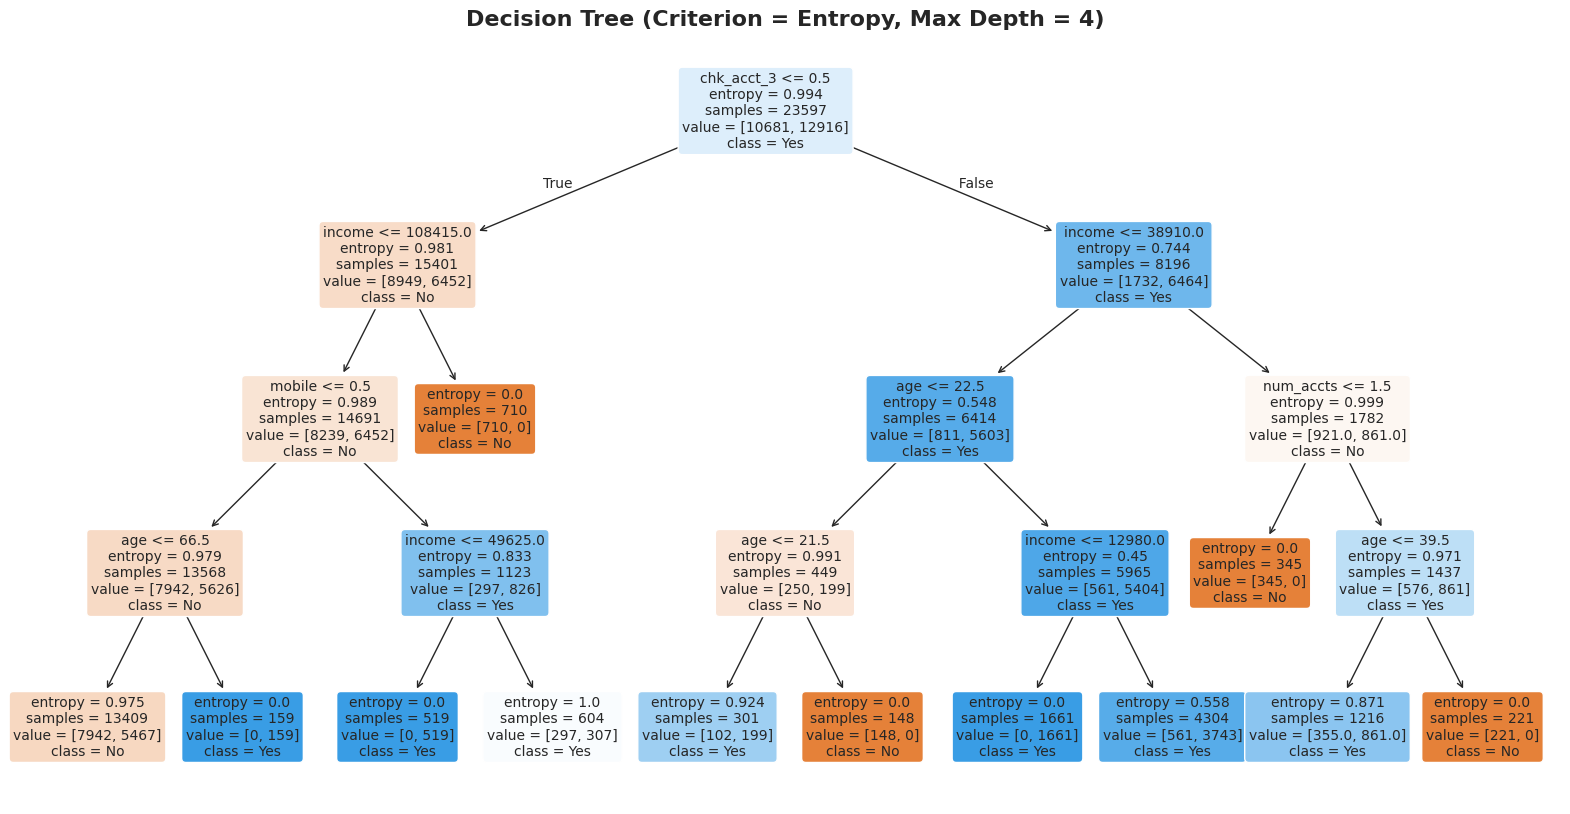

In [83]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
import pandas as pd


X_train_encoded = pd.get_dummies(X_train)
X_test_encoded = pd.get_dummies(X_test)


X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)


dt_model = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
dt_model.fit(X_train_encoded, y_train)


plt.figure(figsize=(20, 10))
plot_tree(dt_model,
          feature_names=X_train_encoded.columns.tolist(),
          class_names=['No', 'Yes'],
          filled=True,
          rounded=True,
          fontsize=10)
plt.title("Decision Tree (Criterion = Entropy, Max Depth = 4)", fontsize=16, fontweight='bold')
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [84]:
from sklearn.metrics import accuracy_score


y_pred = dt_model.predict(X_test_encoded)


model_accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {model_accuracy:.4f} ({model_accuracy * 100:.2f}%)")
print(f"Baseline Probability: {base_prob:.4f} ({base_prob * 100:.2f}%)")
print(f"Difference: {model_accuracy - base_prob:+.4f} ({(model_accuracy - base_prob) * 100:+.2f}%)")

Model Accuracy: 0.7176 (71.76%)
Baseline Probability: 0.5467 (54.67%)
Difference: +0.1709 (+17.09%)


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The model has an accuracy of 71.76%, which is 17.09% higher than the baseline probability of 54.67%.

2. Yes, this is a very significant improvement. By predicting answers with 17% higher accuracy, the company can avoid making many unanswered calls. This allows sales reps to spend their time much more efficiently instead of waiting on silent lines.

### 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [85]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("--- Confusion Matrix ---")
print(cm)
print(f"\nTrue Negatives (TN): {cm[0, 0]}")
print(f"False Positives (FP): {cm[0, 1]}")
print(f"False Negatives (FN): {cm[1, 0]}")
print(f"True Positives (TP): {cm[1, 1]}")

--- Confusion Matrix ---
[[2341  349]
 [1317 1893]]

True Negatives (TN): 2341
False Positives (FP): 349
False Negatives (FN): 1317
True Positives (TP): 1893


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

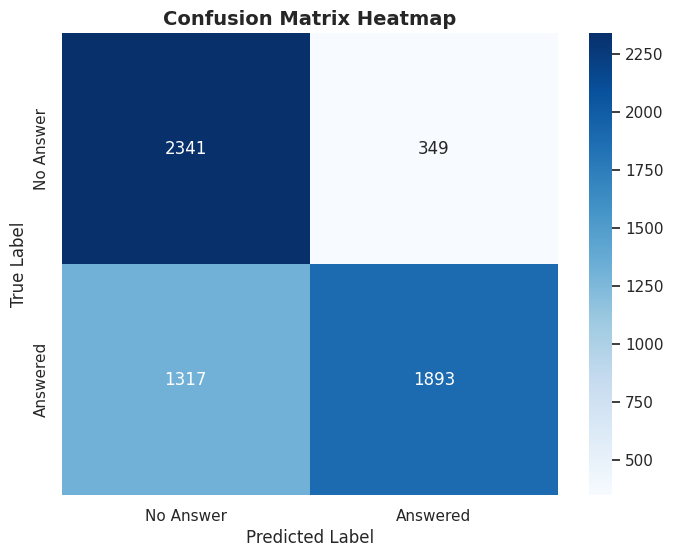

In [86]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Answer', 'Answered'],
            yticklabels=['No Answer', 'Answered'])

plt.title('Confusion Matrix Heatmap', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.show()

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [87]:
tp = cm[1, 1]
fp = cm[0, 1]


profit_model = (tp * 75) - (fp * 25)

print("--- Model Profit Evaluation ---")
print(f"True Positives (Predicted to answer & answered): {tp}")
print(f"False Positives (Predicted to answer & did not answer): {fp}")
print(f"Expected Profit using Model: ${profit_model:,.2f}")

--- Model Profit Evaluation ---
True Positives (Predicted to answer & answered): 1893
False Positives (Predicted to answer & did not answer): 349
Expected Profit using Model: $133,250.00


### 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [88]:
actual_answered = y_test.sum()
actual_no_answer = len(y_test) - actual_answered

profit_call_all = (actual_answered * 75) - (actual_no_answer * 25)

print("--- Default Baseline Profit (Calling Everyone) ---")
print(f"Total Customers in Test Set: {len(y_test)}")
print(f"Actual Answered (TP): {actual_answered}")
print(f"Actual No Answer (FP): {actual_no_answer}")
print(f"Total Baseline Profit: ${profit_call_all:,.2f}")

--- Default Baseline Profit (Calling Everyone) ---
Total Customers in Test Set: 5900
Actual Answered (TP): 3210
Actual No Answer (FP): 2690
Total Baseline Profit: $173,500.00


1. What is the difference in profit?
Calling everyone makes 173500 dollars while calling only the customers recommended by the model makes 133250 dollars. This means calling everyone makes 40250 dollars more in profit.

2. Is this a significant amount?
Yes, it is a big difference of about 23%. However, using the model lets the company skip 62% of the calls and still make 76% of the profit. This is very useful if they do not have enough staff to call everyone.

## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [89]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

tuned_dt = DecisionTreeClassifier(criterion='entropy', max_depth=7, min_samples_split=10, random_state=42)
tuned_dt.fit(X_train_encoded, y_train)

y_pred_tuned = tuned_dt.predict(X_test_encoded)

tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
print(f"Initial Model Accuracy: {model_accuracy * 100:.2f}%")
print(f"Tuned Model Accuracy: {tuned_accuracy * 100:.2f}%")
print(f"Improvement: {(tuned_accuracy - model_accuracy) * 100:+.2f}%")

Initial Model Accuracy: 71.76%
Tuned Model Accuracy: 77.24%
Improvement: +5.47%


### 5.4 Apply the Model to New Customers

### Do the Following
- Import the "adviseinvest_new_customer_data.csv" file
- Copy and past the data cleanup steps from 2.1 and 2.2
- Using the tree model that you created in step 5.3, predict each customer for the target variable by feeding the new customer data into the model
- Predict the number of customers who will be yes/no for the target variable

In [90]:
import pandas as pd


new_cust_url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_new_customer_data.csv'
df_new = pd.read_csv(new_cust_url)

df_new_clean = df_new.drop_duplicates().copy()
df_new_clean = df_new_clean[df_new_clean['income'] >= 0]
df_new_clean = df_new_clean[df_new_clean['age'] < 100]
df_new_clean = df_new_clean[df_new_clean['num_accts'] < 20]

mode_new_car_val = df_clean['new_car'].mode()[0] if 'new_car' in df_clean.columns else 0
df_new_clean['new_car'] = df_new_clean['new_car'].fillna(mode_new_car_val)

df_new_clean = df_new_clean.drop(columns=['customer_id', 'product', 'answered'], errors='ignore')

df_new_clean['new_car'] = df_new_clean['new_car'].astype(int)

categorical_cols = ['job', 'chk_acct', 'sav_acct']
for col in categorical_cols:
    df_new_clean[col] = df_new_clean[col].astype('category')

X_new_encoded = pd.get_dummies(df_new_clean)

X_new_encoded, _ = X_new_encoded.align(X_train_encoded, join='right', axis=1, fill_value=0)

new_predictions = tuned_dt.predict(X_new_encoded)

predictions_series = pd.Series(new_predictions)
counts = predictions_series.value_counts()

print("--- Predictions on New Customers ---")
print(f"Total Cleaned New Customers: {len(df_new_clean)}")
print(f"Predicted to NOT Answer (False): {counts.get(False, 0)}")
print(f"Predicted to Answer (True): {counts.get(True, 0)}")

--- Predictions on New Customers ---
Total Cleaned New Customers: 1000
Predicted to NOT Answer (False): 648
Predicted to Answer (True): 352


# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### Your Response:

6.1: Did we improve our profit using the model?

Yes, indirectly. Calling everyone yields more absolute profit but requires calling 100% of prospects. The model eliminates 62% of wasted calls while still keeping 76.8% of the total profit, which greatly improves efficiency for a small staff of 4 reps.

6.2: How could the model be utilized by the business?

Reps can prioritize and call only the 35.2% of new customers predicted to answer .Managers can dynamically schedule staff based on how many daily leads are predicted to answer. Unlikely responders can be diverted to lower-cost automated text and email campaigns.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [91]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_10_classification.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=Tr

In [93]:
import os

notebook_name = 'assignment_10_classification.ipynb'
target_path = None

for root, dirs, files in os.walk('/content'):
    if notebook_name in files:
        target_path = os.path.join(root, notebook_name)
        break

if target_path:
    print(f"Found notebook at: {target_path}")

    os.system(f'jupyter nbconvert --to html "{target_path}"')
else:
    print("Could not automatically locate the notebook file. Please make sure it is saved in the current directory.")

Found notebook at: /content/assignment_10_classification.ipynb
